# SisFall fall detection: HistGradientBoosting vs GRU

1. Load the raw SisFall trials into one sample-level DataFrame (g, deg/s).
2. Cut each trial into 2.56 s windows and compute summary features per window.
3. Split by **subject** so nobody appears in both train and test.
4. Fit a `HistGradientBoostingClassifier` (fall vs. ADL) and evaluate on the held-out subjects.
5. Train a GRU on the raw windows with the same split and compare.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)

## Load data

In [2]:
sisfall_data_src = "../data/sisfall"
cache_path = "../data/sisfall_samples.parquet"
SAMPLE_HZ = 200

# ADXL345 accel, ITG3200 gyro, MMA8451Q accel
columns = ["ax", "ay", "az", "gx", "gy", "gz", "ax_mma", "ay_mma", "az_mma"]
# Readme: value = [(2*Range)/(2^Resolution)] * counts
scales = np.array([2 * 16 / 2**13] * 3 + [2 * 2000 / 2**16] * 3 + [2 * 8 / 2**14] * 3, dtype=np.float32)


def parse_sisfall(src):
    """Every <CODE>_<SUBJECT>_<TRIAL>.txt under src as one sample-level DataFrame."""
    frames = []
    for folder in sorted(os.listdir(src)):
        folder_path = os.path.join(src, folder)
        if not os.path.isdir(folder_path):
            continue
        for file in sorted(os.listdir(folder_path)):
            if not file.endswith(".txt"):
                continue
            # every line ends in ";" -- treating it as a comment lets the 9th column parse as a number
            counts = pd.read_csv(os.path.join(folder_path, file), header=None, names=columns,
                                 skipinitialspace=True, comment=";", dtype=np.int32)
            data = pd.DataFrame(counts.to_numpy() * scales, columns=columns)
            label, _, trial_no = file.removesuffix(".txt").split("_")
            # subject from the folder: SA15/ has its D17 trials misnamed as D17_SE15_R0x.txt
            data.insert(0, "trial_id", f"{label}_{folder}_{trial_no}")
            data.insert(1, "label", label)
            data.insert(2, "subject_id", folder)
            data.insert(3, "sample", np.arange(len(data), dtype=np.int32))
            frames.append(data)
    df = pd.concat(frames, ignore_index=True)
    for col in ["trial_id", "label", "subject_id"]:
        df[col] = df[col].astype("category")
    df["is_fall"] = df["label"].str.startswith("F")
    return df


if os.path.exists(cache_path):
    df = pd.read_parquet(cache_path)
else:
    df = parse_sisfall(sisfall_data_src)  # ~30 s
    df.to_parquet(cache_path, index=False)

print(df.shape, "|", df["trial_id"].nunique(), "trials")

(15858929, 16) | 4505 trials


## Windows and features

Windows are 512 samples (2.56 s) with 50% overlap.

- **ADL trials:** every window is a negative.
- **Fall trials:** only windows containing the impact (the peak acceleration magnitude in the trial) are positives. The other windows in a fall trial (walking before, lying after) are ambiguous, so they are dropped rather than mislabelled.

In [3]:
WINDOW = 512
STRIDE = WINDOW // 2


def window_features(w):
    """w: (n_windows, WINDOW, 9) -> (n_windows, n_features) summary statistics."""
    acc = np.linalg.norm(w[..., 0:3], axis=-1)       # ADXL345 |a| in g
    gyr = np.linalg.norm(w[..., 3:6], axis=-1)       # ITG3200 |w| in deg/s
    acc_mma = np.linalg.norm(w[..., 6:9], axis=-1)   # MMA8451Q |a| in g
    sig = np.concatenate([w, acc[..., None], gyr[..., None], acc_mma[..., None]], axis=-1)
    feats = [sig.mean(1), sig.std(1), sig.min(1), sig.max(1), np.percentile(sig, [10, 90], axis=1).transpose(1, 0, 2).reshape(len(w), -1)]
    # jerk: how fast acceleration magnitude changes (impacts are sharp)
    jerk = np.abs(np.diff(acc, axis=1)) * SAMPLE_HZ
    feats += [jerk.max(1, keepdims=True), jerk.mean(1, keepdims=True)]
    # how far the trunk tilts: mean gravity direction in the first vs last quarter of the window
    q = WINDOW // 4
    first, last = w[:, :q, 0:3].mean(1), w[:, -q:, 0:3].mean(1)
    cos = (first * last).sum(1) / (np.linalg.norm(first, axis=1) * np.linalg.norm(last, axis=1) + 1e-9)
    feats.append(np.degrees(np.arccos(np.clip(cos, -1, 1)))[:, None])
    return np.concatenate(feats, axis=1)


sig_names = columns + ["acc_mag", "gyr_mag", "acc_mma_mag"]
feature_names = (
    [f"{s}_{stat}" for stat in ["mean", "std", "min", "max"] for s in sig_names]
    + [f"{s}_p{p}" for p in [10, 90] for s in sig_names]
    + ["jerk_max", "jerk_mean", "tilt_deg"]
)

X_parts, y_parts, meta_parts, raw_parts = [], [], [], []
values = df[columns].to_numpy()
for trial_id, idx in df.groupby("trial_id", observed=True).indices.items():
    trial = values[idx]
    starts = np.arange(0, len(trial) - WINDOW + 1, STRIDE)
    w = np.lib.stride_tricks.sliding_window_view(trial, WINDOW, axis=0)[starts].transpose(0, 2, 1)
    label, subject_id, _ = trial_id.split("_")
    is_fall = label.startswith("F")
    if is_fall:
        peak = np.linalg.norm(trial[:, 0:3], axis=1).argmax()
        keep = (starts <= peak) & (peak < starts + WINDOW)
        w, starts = w[keep], starts[keep]
    X_parts.append(window_features(w))
    raw_parts.append(w.astype(np.float32))  # (n, WINDOW, 9) for the GRU
    y_parts.append(np.full(len(w), is_fall))
    meta_parts.append(pd.DataFrame({"trial_id": trial_id, "label": label, "subject_id": subject_id, "start": starts}))

X = pd.DataFrame(np.concatenate(X_parts), columns=feature_names)
y = np.concatenate(y_parts)
meta = pd.concat(meta_parts, ignore_index=True)
W = np.concatenate(raw_parts)  # raw windows, same rows as X
del raw_parts
print(X.shape, "| fall windows:", y.sum(), "| ADL windows:", (~y).sum())

(40704, 75) | fall windows: 3595 | ADL windows: 37109


## Train/test split by subject

Windows from the same person are highly correlated, so the split is by subject. That way the test score measures how well the model generalises to new people. Falls come from the SA subjects plus SE06, so the test set holds out a share of both age groups.

In [4]:
rng = np.random.default_rng(0)
sa = sorted(s for s in meta["subject_id"].unique() if s.startswith("SA"))
se = sorted(s for s in meta["subject_id"].unique() if s.startswith("SE"))
test_subjects = {str(s) for s in [*rng.choice(sa, 5, replace=False), *rng.choice(se, 3, replace=False)]}

test = meta["subject_id"].isin(test_subjects).to_numpy()
X_train, X_test, y_train, y_test = X[~test], X[test], y[~test], y[test]
print("test subjects:", sorted(test_subjects))
print(f"train: {len(y_train)} windows ({y_train.sum()} falls) | test: {len(y_test)} windows ({y_test.sum()} falls)")

test subjects: ['SA06', 'SA08', 'SA11', 'SA13', 'SA17', 'SE10', 'SE11', 'SE14']
train: 32139 windows (2846 falls) | test: 8565 windows (749 falls)


## Fit

trees used: 174


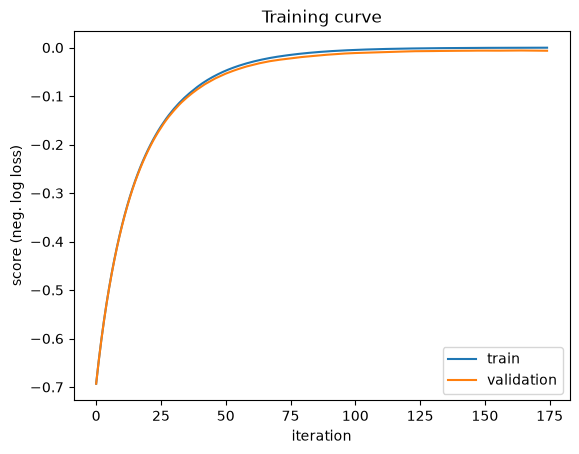

In [5]:
model = HistGradientBoostingClassifier(
    max_iter=500,
    learning_rate=0.05,
    class_weight="balanced",  # ADL windows outnumber falls ~20:1
    early_stopping=True,      # holds out 10% of train to pick the number of trees
    random_state=0,
)
model.fit(X_train, y_train)
print("trees used:", model.n_iter_)

plt.plot(model.train_score_, label="train")
plt.plot(model.validation_score_, label="validation")
plt.xlabel("iteration"); plt.ylabel("score (neg. log loss)"); plt.legend(); plt.title("Training curve")
plt.show()

## Evaluate on held-out subjects

accuracy:          0.9966
balanced accuracy: 0.9951


train accuracy:    0.9999

              precision    recall  f1-score   support

         ADL     0.9994    0.9969    0.9981      7816
        fall     0.9688    0.9933    0.9809       749

    accuracy                         0.9966      8565
   macro avg     0.9841    0.9951    0.9895      8565
weighted avg     0.9967    0.9966    0.9966      8565



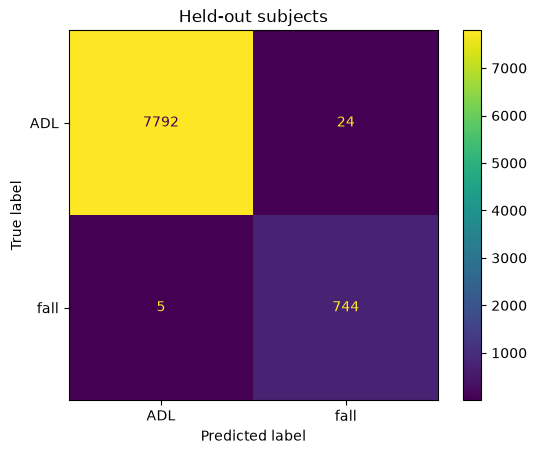

In [6]:
y_pred = model.predict(X_test)

print(f"accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"train accuracy:    {accuracy_score(y_train, model.predict(X_train)):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["ADL", "fall"], digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["ADL", "fall"])
plt.title("Held-out subjects")
plt.show()

Which activities the model gets wrong:

In [7]:
errors = meta[test].assign(correct=(y_pred == y_test))
errors.groupby("label")["correct"].agg(windows="size", accuracy="mean").query("accuracy < 1").sort_values("accuracy")

,windows,accuracy
label,,
D18,200,0.940000
F04,50,0.960000
D14,320,0.962500
F03,49,0.979592
F05,50,0.980000
F08,50,0.980000


## GRU on the raw windows

Same windows, labels and held-out test subjects as above. The difference is the input: the GRU sees the raw 9-channel signal (512 steps × 9 channels, normalised per channel) instead of the 75 hand-made features.

- **Architecture:** a 2-layer bidirectional GRU. Its outputs are mean- and max-pooled over time, since the impact can land anywhere in the window, then passed to a small classification head.
- **Class imbalance:** `pos_weight` in the loss plays the same role as `class_weight="balanced"` for HGB.
- **Early stopping:** uses 4 of the training **subjects** as a validation set, never the test subjects.

In [ ]:
import copy
import time

import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

# validation subjects for early stopping, drawn from the training subjects only (3 adults + 1 elderly)
val_rng = np.random.default_rng(1)
train_sa = sorted(s for s in sa if s not in test_subjects)
train_se = sorted(s for s in se if s not in test_subjects)
val_subjects = {str(s) for s in [*val_rng.choice(train_sa, 3, replace=False), *val_rng.choice(train_se, 1, replace=False)]}
is_val = meta["subject_id"].isin(val_subjects).to_numpy()
tr_idx, val_idx, test_idx = (np.flatnonzero(m) for m in (~test & ~is_val, is_val, test))
print("val subjects:", sorted(val_subjects))
print(f"train {len(tr_idx)} ({y[tr_idx].sum()} falls) | val {len(val_idx)} ({y[val_idx].sum()} falls) | test {len(test_idx)} ({y[test_idx].sum()} falls)")

# per-channel normalisation from the GRU's training windows
mean = W[tr_idx].mean(axis=(0, 1))
std = W[tr_idx].std(axis=(0, 1))
W_dev = torch.from_numpy((W - mean) / std).to(device)  # ~750 MB, fits on the GPU
y_dev = torch.from_numpy(y.astype(np.float32)).to(device)

In [ ]:
class FallGRU(nn.Module):
    def __init__(self, n_in=9, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(n_in, hidden, num_layers=layers, batch_first=True, dropout=dropout, bidirectional=True)
        self.head = nn.Sequential(nn.Linear(4 * hidden, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x):                     # x: (batch, time, channels)
        out, _ = self.gru(x)                  # (batch, time, 2 * hidden)
        pooled = torch.cat([out.mean(1), out.amax(1)], dim=1)
        return self.head(pooled).squeeze(1)   # logits


def predict_proba(net, idx, batch=1024):
    net.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(net(W_dev[idx[i:i + batch]])) for i in range(0, len(idx), batch)]).cpu().numpy()


gru = FallGRU().to(device)
print(f"{sum(p.numel() for p in gru.parameters()):,} parameters")

### Training loop

In [ ]:
EPOCHS = 40
PATIENCE = 6
BATCH = 256

pos_weight = torch.tensor((~y[tr_idx]).sum() / y[tr_idx].sum(), device=device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(gru.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)

history, best_loss, best_state, stale = [], np.inf, None, 0
gen = torch.Generator(device="cpu").manual_seed(0)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    gru.train()
    perm = tr_idx[torch.randperm(len(tr_idx), generator=gen).numpy()]
    total = 0.0
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        opt.zero_grad()
        loss = loss_fn(gru(W_dev[b]), y_dev[b])
        loss.backward()
        nn.utils.clip_grad_norm_(gru.parameters(), 1.0)
        opt.step()
        total += loss.item() * len(b)

    gru.eval()
    with torch.no_grad():
        val_logits = torch.cat([gru(W_dev[val_idx[i:i + 1024]]) for i in range(0, len(val_idx), 1024)])
        val_loss = loss_fn(val_logits, y_dev[val_idx]).item()
    val_pred = (val_logits > 0).cpu().numpy()
    val_bal = balanced_accuracy_score(y[val_idx], val_pred)
    sched.step(val_loss)
    history.append({"epoch": epoch, "train_loss": total / len(perm), "val_loss": val_loss, "val_bal_acc": val_bal})
    print(f"epoch {epoch:2d}  train {total / len(perm):.4f}  val {val_loss:.4f}  val bal-acc {val_bal:.4f}  ({time.time() - t0:.1f}s)")

    if val_loss < best_loss:
        best_loss, best_state, stale = val_loss, copy.deepcopy(gru.state_dict()), 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print("early stop")
            break

gru.load_state_dict(best_state)
hist = pd.DataFrame(history).set_index("epoch")
print("best epoch:", hist["val_loss"].idxmin())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=ax[0], title="GRU loss")
hist["val_bal_acc"].plot(ax=ax[1], title="GRU validation balanced accuracy")
plt.show()

### Evaluate the GRU on the held-out subjects

In [ ]:
y_pred_gru = predict_proba(gru, test_idx) > 0.5

print(f"accuracy:          {accuracy_score(y_test, y_pred_gru):.4f}")
print(f"balanced accuracy: {balanced_accuracy_score(y_test, y_pred_gru):.4f}")
print()
print(classification_report(y_test, y_pred_gru, target_names=["ADL", "fall"], digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gru, display_labels=["ADL", "fall"])
plt.title("GRU, held-out subjects")
plt.show()

## HistGradientBoosting vs GRU

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score


def summary(pred):
    return {
        "accuracy": accuracy_score(y_test, pred),
        "balanced accuracy": balanced_accuracy_score(y_test, pred),
        "fall recall": recall_score(y_test, pred),
        "fall precision": precision_score(y_test, pred),
        "fall F1": f1_score(y_test, pred),
        "missed falls": int((y_test & ~pred).sum()),
        "false alarms": int((~y_test & pred).sum()),
    }


comparison = pd.DataFrame({"HistGradientBoosting": summary(y_pred), "GRU": summary(y_pred_gru)})
comparison.round(4)

In [ ]:
# per-activity accuracy where either model makes mistakes
per_activity = meta[test].assign(HGB=(y_pred == y_test), GRU=(y_pred_gru == y_test))
acc = per_activity.groupby("label")[["HGB", "GRU"]].mean()
acc[(acc < 1).any(axis=1)].round(3).sort_values("GRU")